In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Análise Exploratória de Dados de Alfabetização, Enriquecidos com Dados Públicos

Nosso objetivo principal é compreender o comportamento de variáveis potenciais para descrever as chances de alfabetização de um aluno da rede pública do Brasil. Evidentemente, o dataset que alimentará o modelo de ML não irá se resumir às variáveis que demonstraram maior correlação com a variável alvo, visto que tais relações podem implicar em data leakage, colinearidade e compreendendo também que dados que não demonstram correlação linear podem, mesmo assim, influenciar em modelos mais robustos. Tendo isso em mente, a análise exploratória será relevante para compreender padrões mais evidentes, encontrar variáveis redundantes, com grau elevado de colinearidade, ou que possuem relações que ajudam a explicar a variável alvo, para permitir que interpretemos de forma mais relevante os resultados obtidos.

## 1. Compreensão do Comportamento e Distribuição dos Dados 

In [2]:
# Carrega o dataset mantendo exatamente os tipos int8, float32 e category
df_EDA = pd.read_parquet('gold_dataset_to_EDA.parquet', engine='pyarrow')

df_EDA.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5320622 entries, 0 to 5320621
Data columns (total 48 columns):
 #   Column                              Dtype   
---  ------                              -----   
 0   year                                int16   
 1   state_code                          int8    
 2   school_id                           object  
 3   education_network_type              int8    
 4   city_code                           int32   
 5   student_exam_weight                 float32 
 6   student_exam_score                  float32 
 7   student_is_literate                 int8    
 8   city_name                           category
 9   city_percentage_literate_students   float32 
 10  city_average_exam_score             float32 
 11  state_abbreviation                  category
 12  state_percentage_literate_students  float32 
 13  state_average_exam_score            float32 
 14  households                          int32   
 15  area                            

### 1.1. Distribuição da Variável Alvo (student_is_literate)

O objetivo desta etapa é avaliar o balanceamento da variável que o modelo de Machine Learning tentará prever, o student_is_literate. Compreender a proporção exata entre alunos alfabetizados (1) e não alfabetizados (0) é o primeiro passo para compreender se o algoritmo corre o risco de ficar enviesado e apenas prever a classe majoritária, o que exigirá uma metodologia mais robusta para lidar com esse desequilíbrio.

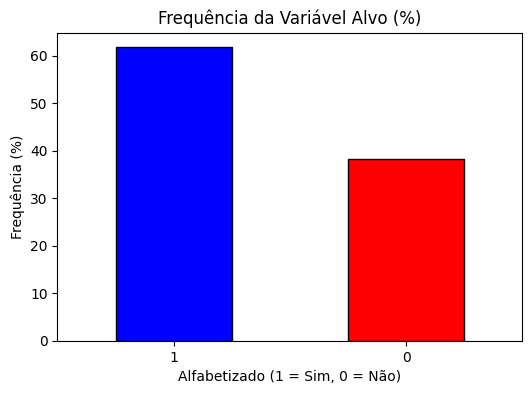

Frequência exata da Variável Alvo (%):
student_is_literate
1    61.780728
0    38.219272
Name: proportion, dtype: float64
----------------------------------------


In [3]:
# Calcula a frequência relativa (percentual)
frequencia_alvo = df_EDA['student_is_literate'].value_counts(normalize=True) * 100

# Configura e plota o gráfico de barras
plt.figure(figsize=(6, 4))
frequencia_alvo.plot(
        kind='bar', 
        color=['blue', 'red'], 
        edgecolor='black'
)

plt.title('Frequência da Variável Alvo (%)')
plt.xlabel('Alfabetizado (1 = Sim, 0 = Não)')
plt.ylabel('Frequência (%)')
plt.xticks(rotation=0)
plt.show()

# Exibe a proporção exata em texto no terminal
print("Frequência exata da Variável Alvo (%):")
print(frequencia_alvo)
print("-" * 40)

Como pudemos notar, encontramos uma proporção aproximada de 61.8%/38.2%. Esse é um cenário bastante equilibrado, o que evita a aplicação de metodologias mais robustas na etapa de aplicação do modelo.

### 1.2. Análise de Distribuições Numéricas

Iremos iniciar a verificação pela análise descritiva dos dados. Assim, conseguiremos interpretar padrões mais evidentes e que podem nos dar insights mais imediatos para corroborar a natureza dos dados.

#### Análise Descritiva dos Dados

In [4]:
# Seleciona apenas as colunas numéricas, excluindo a variável alvo
cols_numericas = df_EDA.select_dtypes(include=['number']).columns.drop('student_is_literate')

# Gera o resumo estatístico completo e transpõe para facilitar a leitura horizontal
estatisticas_completas = df_EDA[cols_numericas].describe().T

# Formata a exibição para evitar notação científica
pd.options.display.float_format = '{:.2f}'.format

print("--- Estatísticas Descritivas ---")
display(estatisticas_completas)

--- Estatísticas Descritivas ---


,count,mean,std,min,25%,50%,75%,max
year,5320622.00,2024.09,0.80,2023.00,2023.00,2024.00,2025.00,2025.00
state_code,5320622.00,32.10,10.21,11.00,26.00,32.00,41.00,53.00
education_network_type,5320622.00,2.88,0.32,2.00,3.00,3.00,3.00,3.00
city_code,5320622.00,3224787.38,1022830.58,1100015.00,2601052.00,3202405.00,4104808.00,5300108.00
student_exam_weight,5320622.00,1.14,0.30,0.10,1.03,1.10,1.20,142.55
student_exam_score,5320622.00,750.30,47.81,572.36,722.69,756.14,782.01,904.38
city_percentage_literate_students,5320622.00,61.49,15.79,2.12,50.88,61.61,72.22,100.00
city_average_exam_score,5320622.00,749.98,20.18,673.30,737.11,747.79,759.24,871.26
state_percentage_literate_students,5320622.00,61.25,11.62,30.57,55.35,59.61,70.43,86.21
state_average_exam_score,5320622.00,749.73,15.23,712.56,741.15,747.32,757.24,797.34


A análise descritiva do dataset nos permitiu ter alguns insights interessantes. A variável null_teacher_schools_count apresenta todas as medidas estatísticas iguais a 0. Ou seja, por ser uma constante, ela não oferece qualquer poder preditivo ao algoritmo, visto que os dados presentes em todos os casos para tal variável serão os mesmo. Por esse motivo, entendemos que tal variável deve ser descartada da base.

A variável sex_ratio possui um valor máximo de 443.64. Isso indica uma cidade uma proporção bastante elevada de homens em relação a mulheres em um determinado município. Uma possível explicação para tal discrepância pode ser o fato desses dados virem de municípios com complexos penitenciários, bases militares, acampamentos de mineração ou outros casos que estimulem a alta concentração de presença masculina.

Os máximos de students_per_teacher (78.42) e students_per_class (70.95) apontam para turmas com superlotação em partes específicas da base. Será interessante notar como tais realidades afetam a educação, visto que se impõe uma dificuldade óbvia de organizar, ensinar e lidar com alunos em uma condição possivelmente caótica, que deve gerar impactos significativos no aprendizado.

Variáveis absolutas como population_total (de 833 a 11,4 milhões) e fundeb_amount (de 0 a mais de 8 bilhões) possuem uma discrepância gigantesca entre o percentil 75% e o valor máximo. Esse é um comportamente esperado, visto que algumas metrópoles como Rio de Janeiro, São Paulo e Salvador, concentram um grande número de pessoas, enquanto a maior parte dos municípios, principalmente os de interior, possuem populações em uma ordem de grandeza bem mais baixa. Esse comportamente é bastante característico de variáveis que podem ser linearizadas por transformação logarítmica.

Em relação aos dados raciais, notamos a baixa quantidade média de indígenas e descendentes de asiáticos. Há uma concentração discrepante no valor máximo de amarelos, que são asiáticos e descendentes de asiáticos com características fenotípicos compatíveis, que fica próxima de 11%, provavelmente referente à cidade de Assaí, no Paraná, que é conhecida pela forte colônia asiática presente na região. Já em relação aos indígenas, embora exista presença indígena em municípios espalhados pelo território nacional, há uma concentração discrepante de tais populações no Norte do país. Há inclusive município quase completamente compostos por indígenas.

Por último, encontramos diversas variáveis com medianas e médias bastante discrepantes e desvios padrão que ultrapassam tais valores, como é o caso das variáveis fundeb_amount, population_total, households e total_teachers. Isso demonstra uma evidência de assimetria severa nessas variáveis. A enorme maioria dos municípios brasileiros é pequena e tem valores baixos, o que puxa a mediana para baixo. No entanto, algumas poucas megalópoles (como São Paulo e Rio de Janeiro) possuem valores tão absurdamente altos que "arrastam" a média para cima e explodem o desvio padrão.

In [3]:
# Remoção da variável com variância zero (constante)
if 'null_teacher_schools_count' in df_EDA.columns:
    df_EDA = df_EDA.drop(columns=['null_teacher_schools_count'])
    print("Coluna 'null_teacher_schools_count' removida com sucesso!")

# Confirmação da estrutura atual do DataFrame
print(f"Dimensões atuais do df_EDA: {df_EDA.shape}")

Coluna 'null_teacher_schools_count' removida com sucesso!
Dimensões atuais do df_EDA: (5320622, 47)


#### Distribuição: Dados Socioeconômicos

O objetivo deste etapa é visualizar graficamente o comportamento da distribuição de rendimento e financiamento estrutural. Variáveis financeiras como o repasse do FUNDEB (fundeb_amount) e a renda per capita (income_per_capita_mean), a depender da distribuição, podem nos mostrar insights relevantes sobre a desigualdade entre municípios que em sua maioria são de baixa renda e poucos recursos, em comparação com uma pequena minoria concentra valores altíssimos. A forma da distribuição pode nos dar pistas desse padrão.

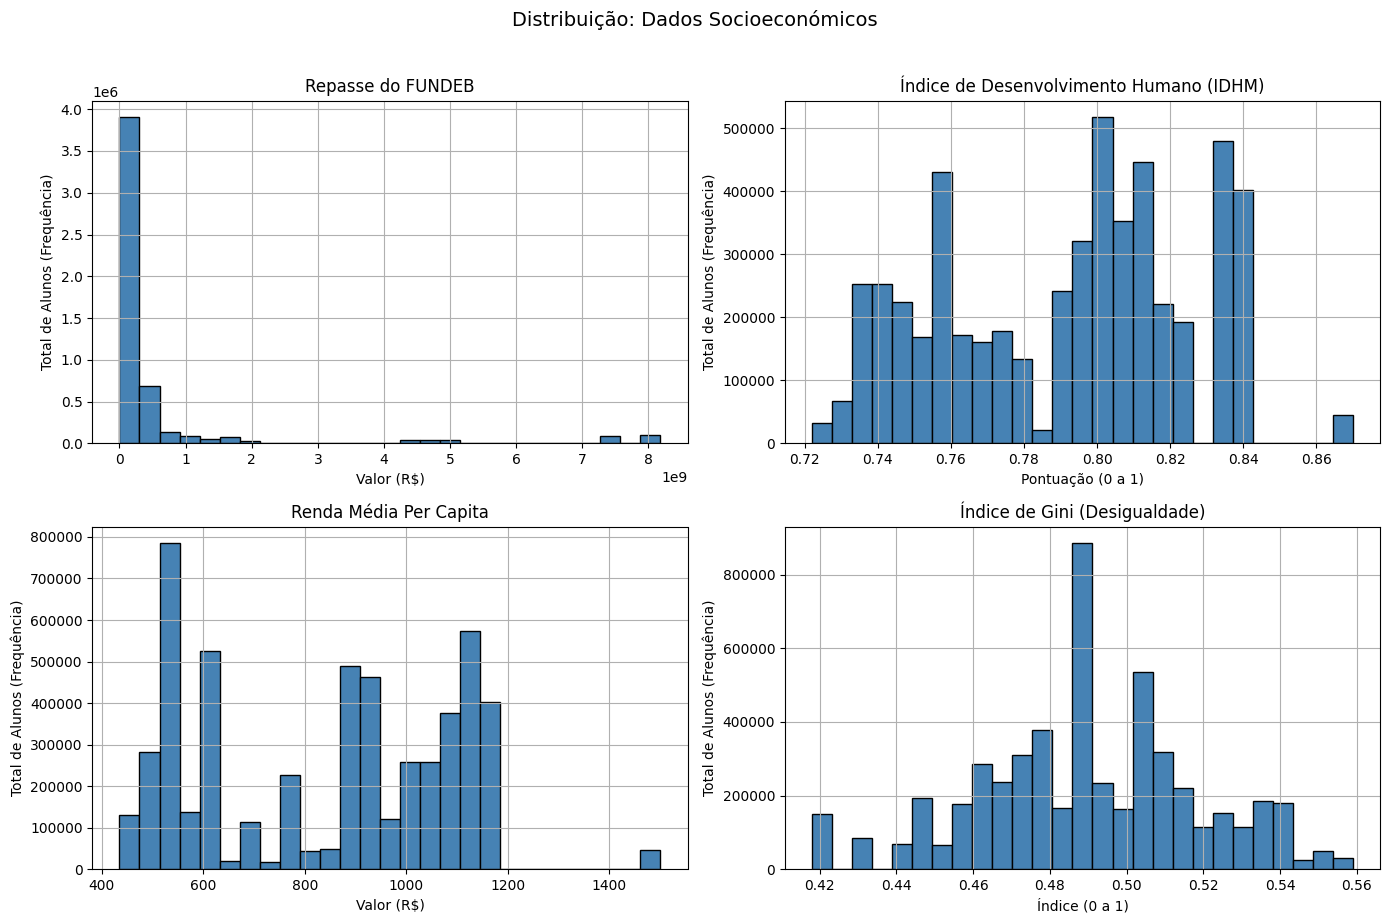

In [11]:
cols_socioeconomicas = ['fundeb_amount', 'hdi', 'income_per_capita_mean', 'gini_index']
titulos = [
    'Repasse do FUNDEB', 
    'Índice de Desenvolvimento Humano (IDHM)', 
    'Renda Média Per Capita', 
    'Índice de Gini (Desigualdade)'
]
rotulos_x = [
    'Valor (R$)', 
    'Pontuação (0 a 1)', 
    'Valor (R$)', 
    'Índice (0 a 1)'
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for i, col in enumerate(cols_socioeconomicas):
    # 27 bins para alinhar diretamente com as 27 UFs do país
    df_EDA[col].hist(bins=27, ax=axes[i], edgecolor='black', color='steelblue')
    axes[i].set_title(titulos[i])
    axes[i].set_xlabel(rotulos_x[i])
    axes[i].set_ylabel('Total de Alunos (Frequência)')

plt.suptitle('Distribuição: Dados Socioeconómicos', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

A visualização das distribuições socioeconômicas evidencia um contraste entre o investimento público e os indicadores estruturais regionais:

A variável fundeb_amount exibe uma assimetria à direita extremamente acentuada, que condiz com os dados obtidos via estatística descritiva, concentrando a grande maioria dos estudantes em municípios com repasses de menor porte e projetando outliers isolados na casa dos bilhões para as grandes metrópoles. Esse diagnóstico justifica a aplicação de transformação logarítmica na etapa de Engenharia de Atributos, prevenindo que modelos sejam distorcidos por essa amplitude.

Os indicadores agregados em nível estadual (hdi, gini_index e income_per_capita_mean) apresentam distribuições multimodais com picos bem definidos. Em vez de uma variação contínua individual, esses picos refletem a alocação de volumosas massas de alunos dentro dos patamares macroeconômicos de suas UFs, com destaque para o pico do Índice de Gini em 0,49, que abrange mais de 750 mil estudantes e que é compatível com o índice de Gini do Estado de São Paulo.

#### Dados Demográficos

Mapear a distribuição gráfica das variáveis demográficas (population_total, literacy_rate, aging_index, sex_ratio, pct_black, pct_brown). O intuito é identificar assimetrias de escala populacional, variações étnico-raciais e distorções demográficas regionais que possam influenciar o contexto de alfabetização dos estudantes.

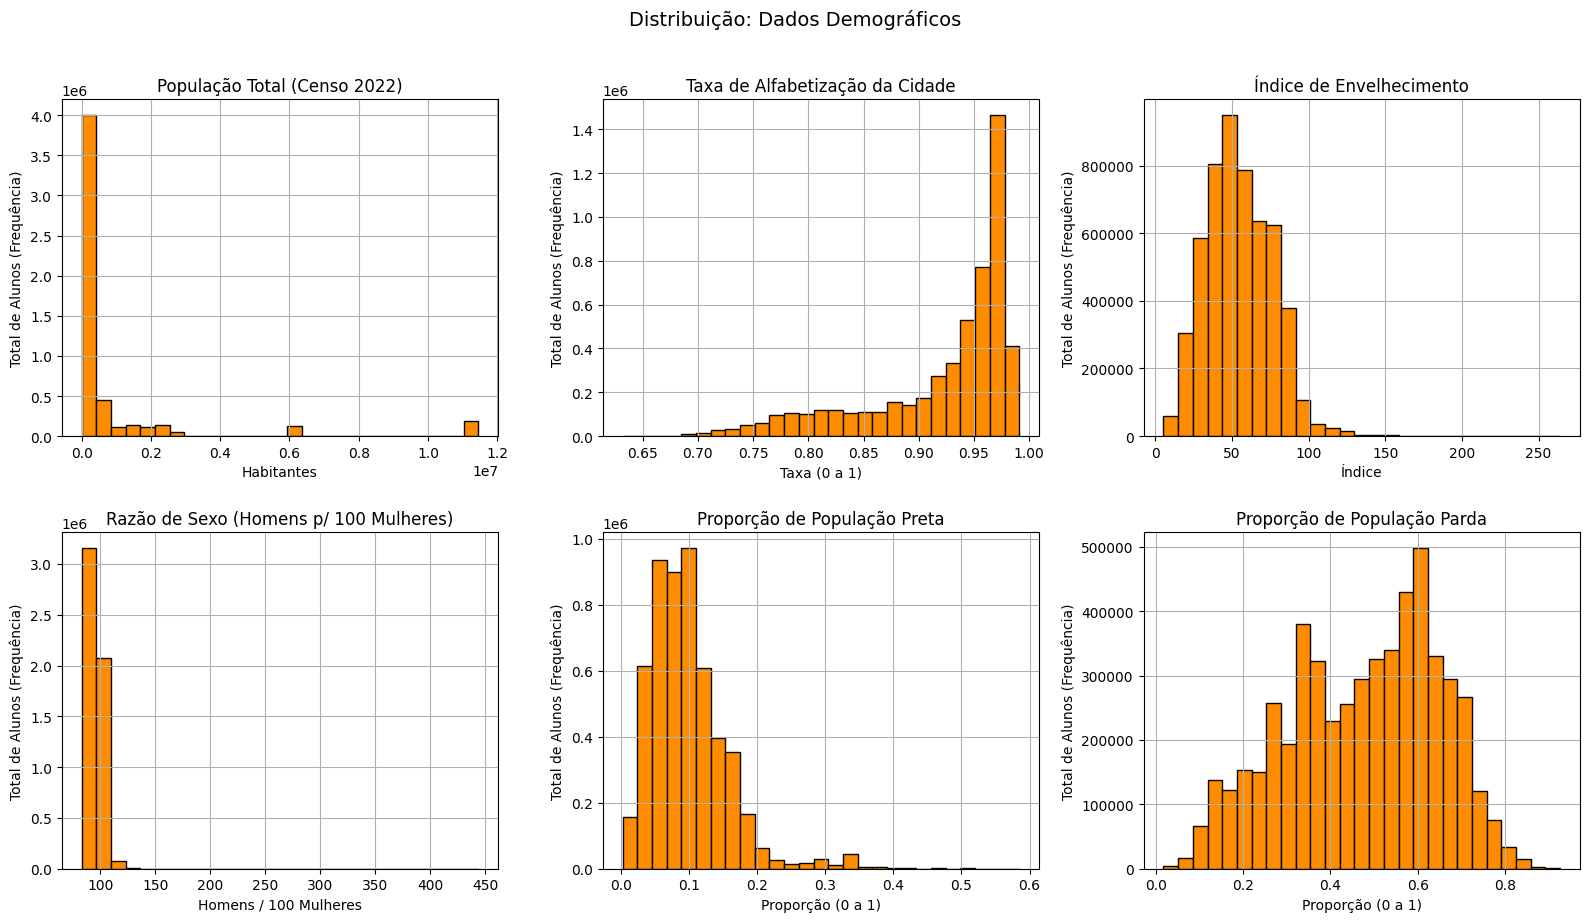

In [13]:
cols_demograficas = ['population_total', 'literacy_rate', 'aging_index', 'sex_ratio', 'pct_black', 'pct_brown']
titulos_demo = [
    'População Total (Censo 2022)', 
    'Taxa de Alfabetização da Cidade', 
    'Índice de Envelhecimento', 
    'Razão de Sexo (Homens p/ 100 Mulheres)',
    'Proporção de População Preta',
    'Proporção de População Parda'
]
rotulos_x_demo = [
    'Habitantes', 
    'Taxa (0 a 1)', 
    'Índice', 
    'Homens / 100 Mulheres',
    'Proporção (0 a 1)',
    'Proporção (0 a 1)'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(cols_demograficas):
    # Padronizado com 27 bins para todas as variáveis demográficas
    df_EDA[col].hist(bins=27, ax=axes[i], edgecolor='black', color='darkorange')
    axes[i].set_title(titulos_demo[i])
    axes[i].set_xlabel(rotulos_x_demo[i])
    axes[i].set_ylabel('Total de Alunos (Frequência)')

plt.suptitle('Distribuição: Dados Demográficos', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

A assimetria positiva de population_total está evidente, acumulando a imensa maioria da massa escolar na primeira barra (municípios pequenos/médios) e isolando grandes centros urbanos na extrema direita. A variável literacy_rate agrupa a maior frequência de alunos nas faixas superiores (entre 0,90 e 0,96), evidenciando que municípios com baixos índices gerais de alfabetização representam um grupo reduzido e de alta vulnerabilidade.

O aging_index mostra uma grande concentração no intervalo central de 35 a 65, enquanto a sex_ratio centraliza-se na faixa de 90 a 100 homens por 100 mulheres, isolando com clareza a anomalia pontual próxima a 443. Essa anomalia foi discutida anteriormente, na etapa de estatística descritiva. A proporção de população parda (pct_brown) apresenta formato próximo ao bimodal, com picos locais nas faixas de 0,30-0,40 e 0,50–0,70, que pode ter a ver com a concentração dessas faixas de porcentagem em regiões geográficas específicas do Brasil, enquanto a de população preta (pct_black) distribui-se majoritariamente nos intervalos de 0,05 a 0,15. Isso demonstra uma presenta massiva de pessoas negras (pretos e pardos afrodescendentes) distribuídas pelo Brasil.

A padronização em 27 bins unificou a resolução gráfica entre as análises socioeconômica e demográfica. Os resultados ratificam que algumas variáveis precisarão de transformação logarítmica, enquanto os demais indicadores demográficos apresentam distribuições bem delimitadas.

#### Contexto Escolar

Verificar a distribuição das variáveis atreladas à educação e à infraestrutura das escolas (students_per_class, students_per_teacher, age_lag_2y_basic_rate, pct_internet_schools). O intuito é diagnosticar a densidade de alunos por turma, a carga docente, a defasagem idade-série e o nível de conectividade, fatores com potencial de afetar a alfabetização.

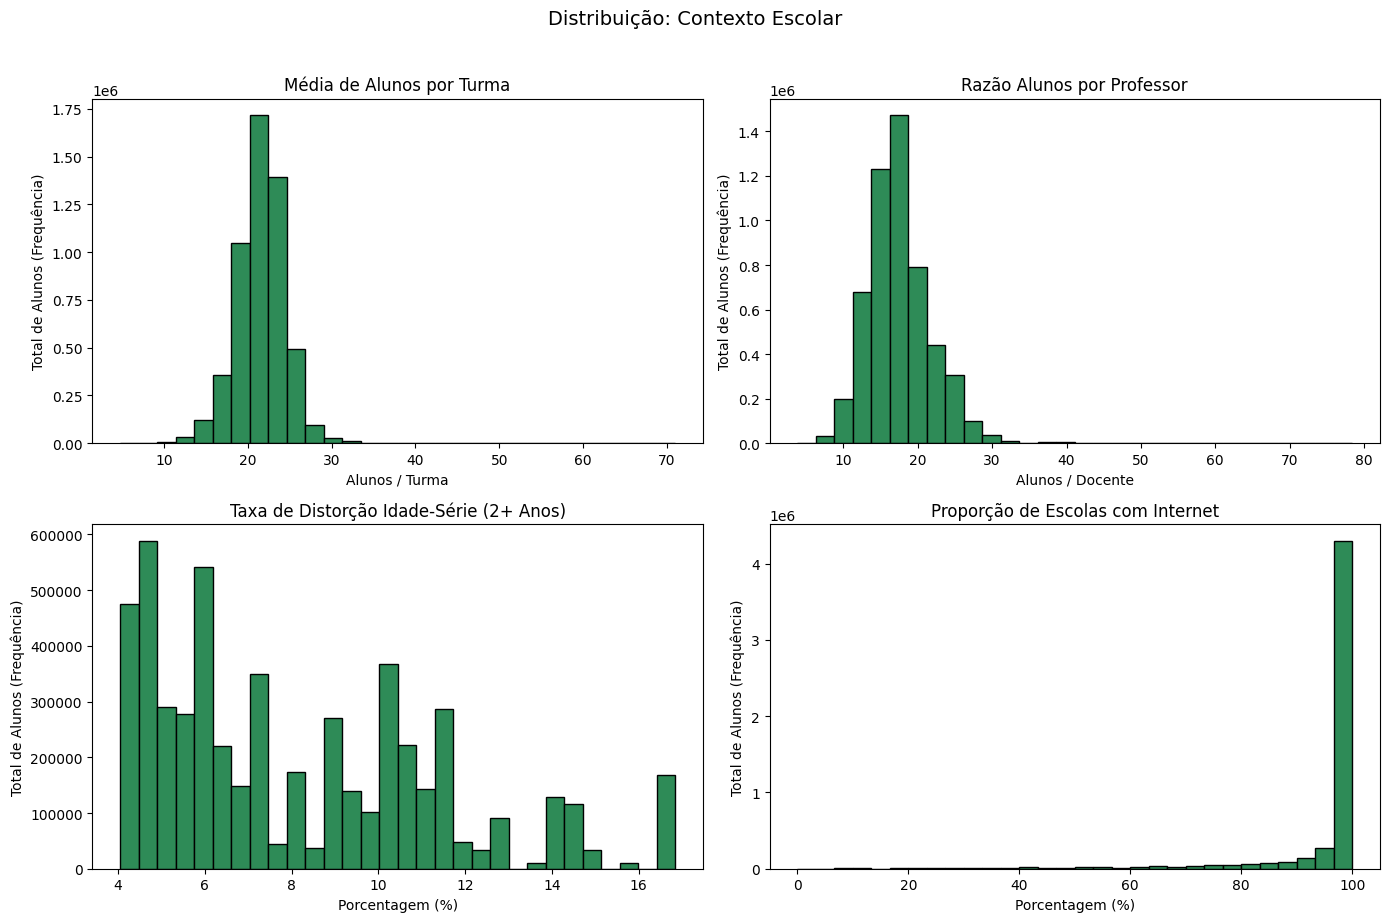

In [17]:
cols_escolares = [
    'students_per_class', 
    'students_per_teacher', 
    'age_lag_2y_basic_rate', 
    'pct_internet_schools'
]
titulos_esc = [
    'Média de Alunos por Turma', 
    'Razão Alunos por Professor', 
    'Taxa de Distorção Idade-Série (2+ Anos)', 
    'Proporção de Escolas com Internet'
]
rotulos_x_esc = [
    'Alunos / Turma', 
    'Alunos / Docente', 
    'Porcentagem (%)', 
    'Porcentagem (%)'
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for i, col in enumerate(cols_escolares):
    dados_validos = df_EDA[col].dropna().astype(float)
    axes[i].hist(dados_validos, bins=30, edgecolor='black', color='seagreen')
    axes[i].set_title(titulos_esc[i])
    axes[i].set_xlabel(rotulos_x_esc[i])
    axes[i].set_ylabel('Total de Alunos (Frequência)')

plt.suptitle('Distribuição: Contexto Escolar', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

A distribuição dos alunos por turma se assemelha a uma curva normal, com a maioria dos alunos em turmas de 15 a 30 estudantes. O pico ocorre no intervalo logo acima de 20 alunos por sala. O students_per_teacher apresenta comportamento simétrico, assim como a variável anterior, e altamente concentrado, com o grande volume distribuído entre 10 e 25 alunos por professor. O pico principal destaca-se no intervalo entre 15 e 20 alunos para cada professor.

A variável age_lag_2y_basic_rate exibe um comportamento irregular e multimodal, variando predominantemente na faixa de 4% a 17%. Em vez de uma queda suave, observam-se concentrações com taxas em torno de 5%, 6%, 10% a 11%, e um agrupamento próximo aos 17%. Esse padrão pode ter a ver com características das regiões geográficas que concentram os dados em torno de vários pontos de máximo. O acesso à internet revela uma assimetria negativa extrema. Uma proporção grande de estudantes, ultrapassando a marca de 4 milhões na frequência, encontra-se no limite máximo, próximo a 100% de conectividade. Isso indica que a ausência de internet escolar é uma exceção severa na rede analisada. 

Os gráficos reais evidenciam realidades distintas dentro do ecossistema escolar. Enquanto os recursos humanos e o tamanho das turmas seguem distribuições equilibradas e próximas à normalidade, a infraestrutura (internet) é um serviço quase universalizado, tornando os poucos casos sem acesso fortes indicadores de isolamento. A distorção idade-série, com seus diversos picos, sugere que o atraso escolar não é um fenômeno homogêneo, mas sim agrupado em perfis específicos de escolas e regiões.

### 1.3 Análise das Variáveis Categóricas

O objetivo desse tópico é mapear a distribuição de frequência absoluta das principais variáveis categóricas de nível estrutural: a rede de ensino (education_network_type) e a Unidade Federativa (state_abbreviation). O intuito é identificar o volume de alunos sob responsabilidade municipal versus estadual/federal e avaliar a representatividade de cada estado na base de dados, garantindo que não haja desbalanceamentos que impactem o modelo.

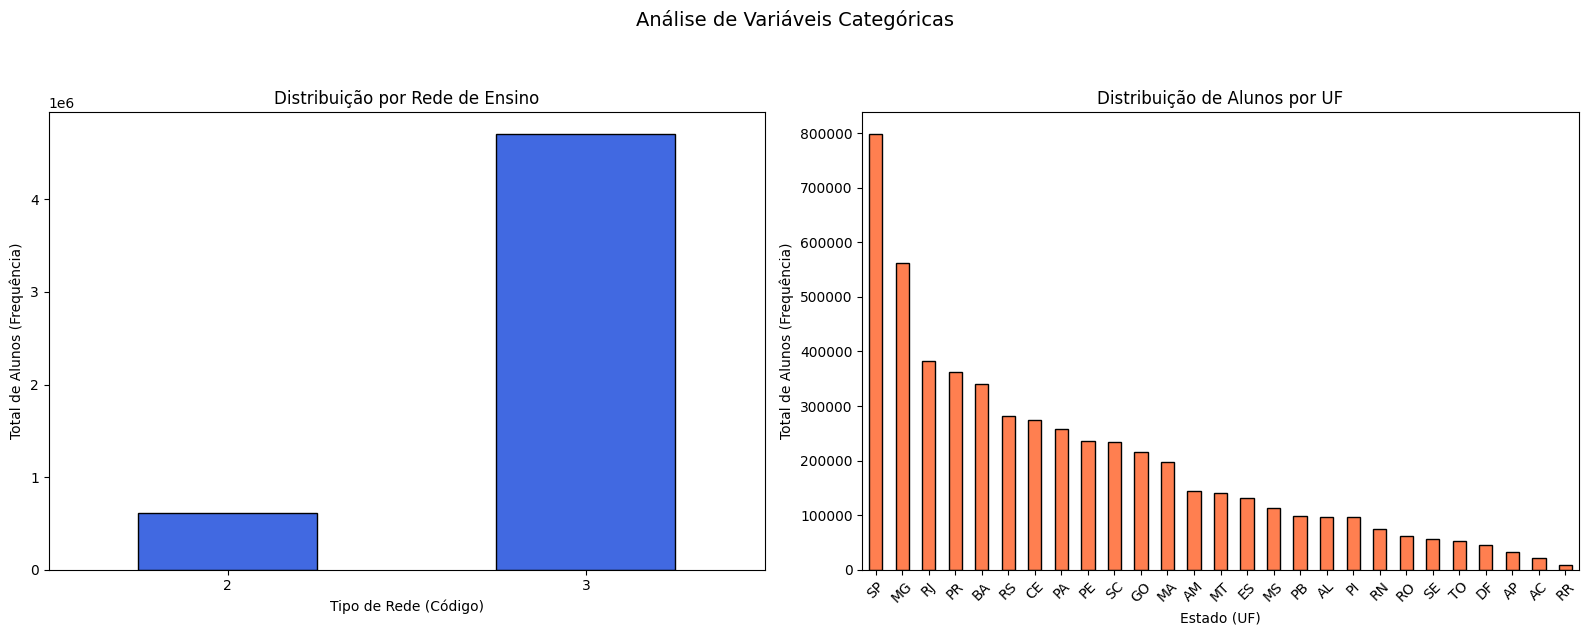

In [18]:
# Contagem e visualização das variáveis categóricas
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Rede de Ensino
if 'education_network_type' in df_EDA.columns:
    df_EDA['education_network_type'].value_counts().sort_index().plot(
        kind='bar', ax=axes[0], color='royalblue', edgecolor='black'
    )
    axes[0].set_title('Distribuição por Rede de Ensino')
    axes[0].set_xlabel('Tipo de Rede (Código)')
    axes[0].set_ylabel('Total de Alunos (Frequência)')
    axes[0].tick_params(axis='x', rotation=0)

# Gráfico 2: Unidade Federativa
if 'state_abbreviation' in df_EDA.columns:
    df_EDA['state_abbreviation'].value_counts().plot(
        kind='bar', ax=axes[1], color='coral', edgecolor='black'
    )
    axes[1].set_title('Distribuição de Alunos por UF')
    axes[1].set_xlabel('Estado (UF)')
    axes[1].set_ylabel('Total de Alunos (Frequência)')
    axes[1].tick_params(axis='x', rotation=45)

plt.suptitle('Análise de Variáveis Categóricas', y=1.05, fontsize=14)
plt.tight_layout()
plt.show()

O gráfico revela uma concentração evidente na rede número 3 (municipal), que agrega a grande maioria da base, a ultrapassar os 4,5 milhões de alunos. A rede de número 2 (estadual) tem uma representatividade manifestamente inferior, em torno dos 600 mil alunos. Este cenário traduz o contexto estrutural do Brasil, onde a responsabilidade pelos anos iniciais e alfabetização recai predominantemente sobre os municípios. 

A distribuição estadual é liderada de forma destacada por São Paulo (SP), com aproximadamente 800 mil alunos, seguido por Minas Gerais (MG) com cerca de 550 mil e Rio de Janeiro (RJ) próximo dos 380 mil. O decréscimo é contínuo e acompanha o peso demográfico nacional, terminando em estados da região Norte, como o Acre (AC) e Roraima (RR), que apresentam as menores frequências absolutas. A análise categórica valida que a base de dados apresenta de forma precisa a distribuição populacional e administrativa do ensino básico no país. A forte discrepância entre as redes de ensino (education_network_type) confirma a necessidade de aplicar a técnica de One-Hot Encoding na fase de engenharia de atributos.

## 2. Identificação de Padrões e Formulação de Hipóteses Analíticas

O objetivo desta etapa é cruzar a variável alvo com os atributos para analisar variáveis relevantes e formular hipóteses analíticas, respondendo diretamente às perguntas de negócio.

### 2.1. Fatores de Impacto na Alfabetização

Buscamos mapear e comparar a distribuição de indicadores estruturais entre os grupos de alunos alfabetizados e não alfabetizados, identificando quais dimensões exercem influência ou diferenciação sobre o sucesso no processo de alfabetização infantil.

C:\Users\andre\AppData\Local\Temp\ipykernel_3532\4046075454.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\andre\AppData\Local\Temp\ipykernel_3532\4046075454.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\andre\AppData\Local\Temp\ipykernel_3532\4046075454.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\andre\AppData\Local\Temp\ipykernel_3532\4046075454.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` 

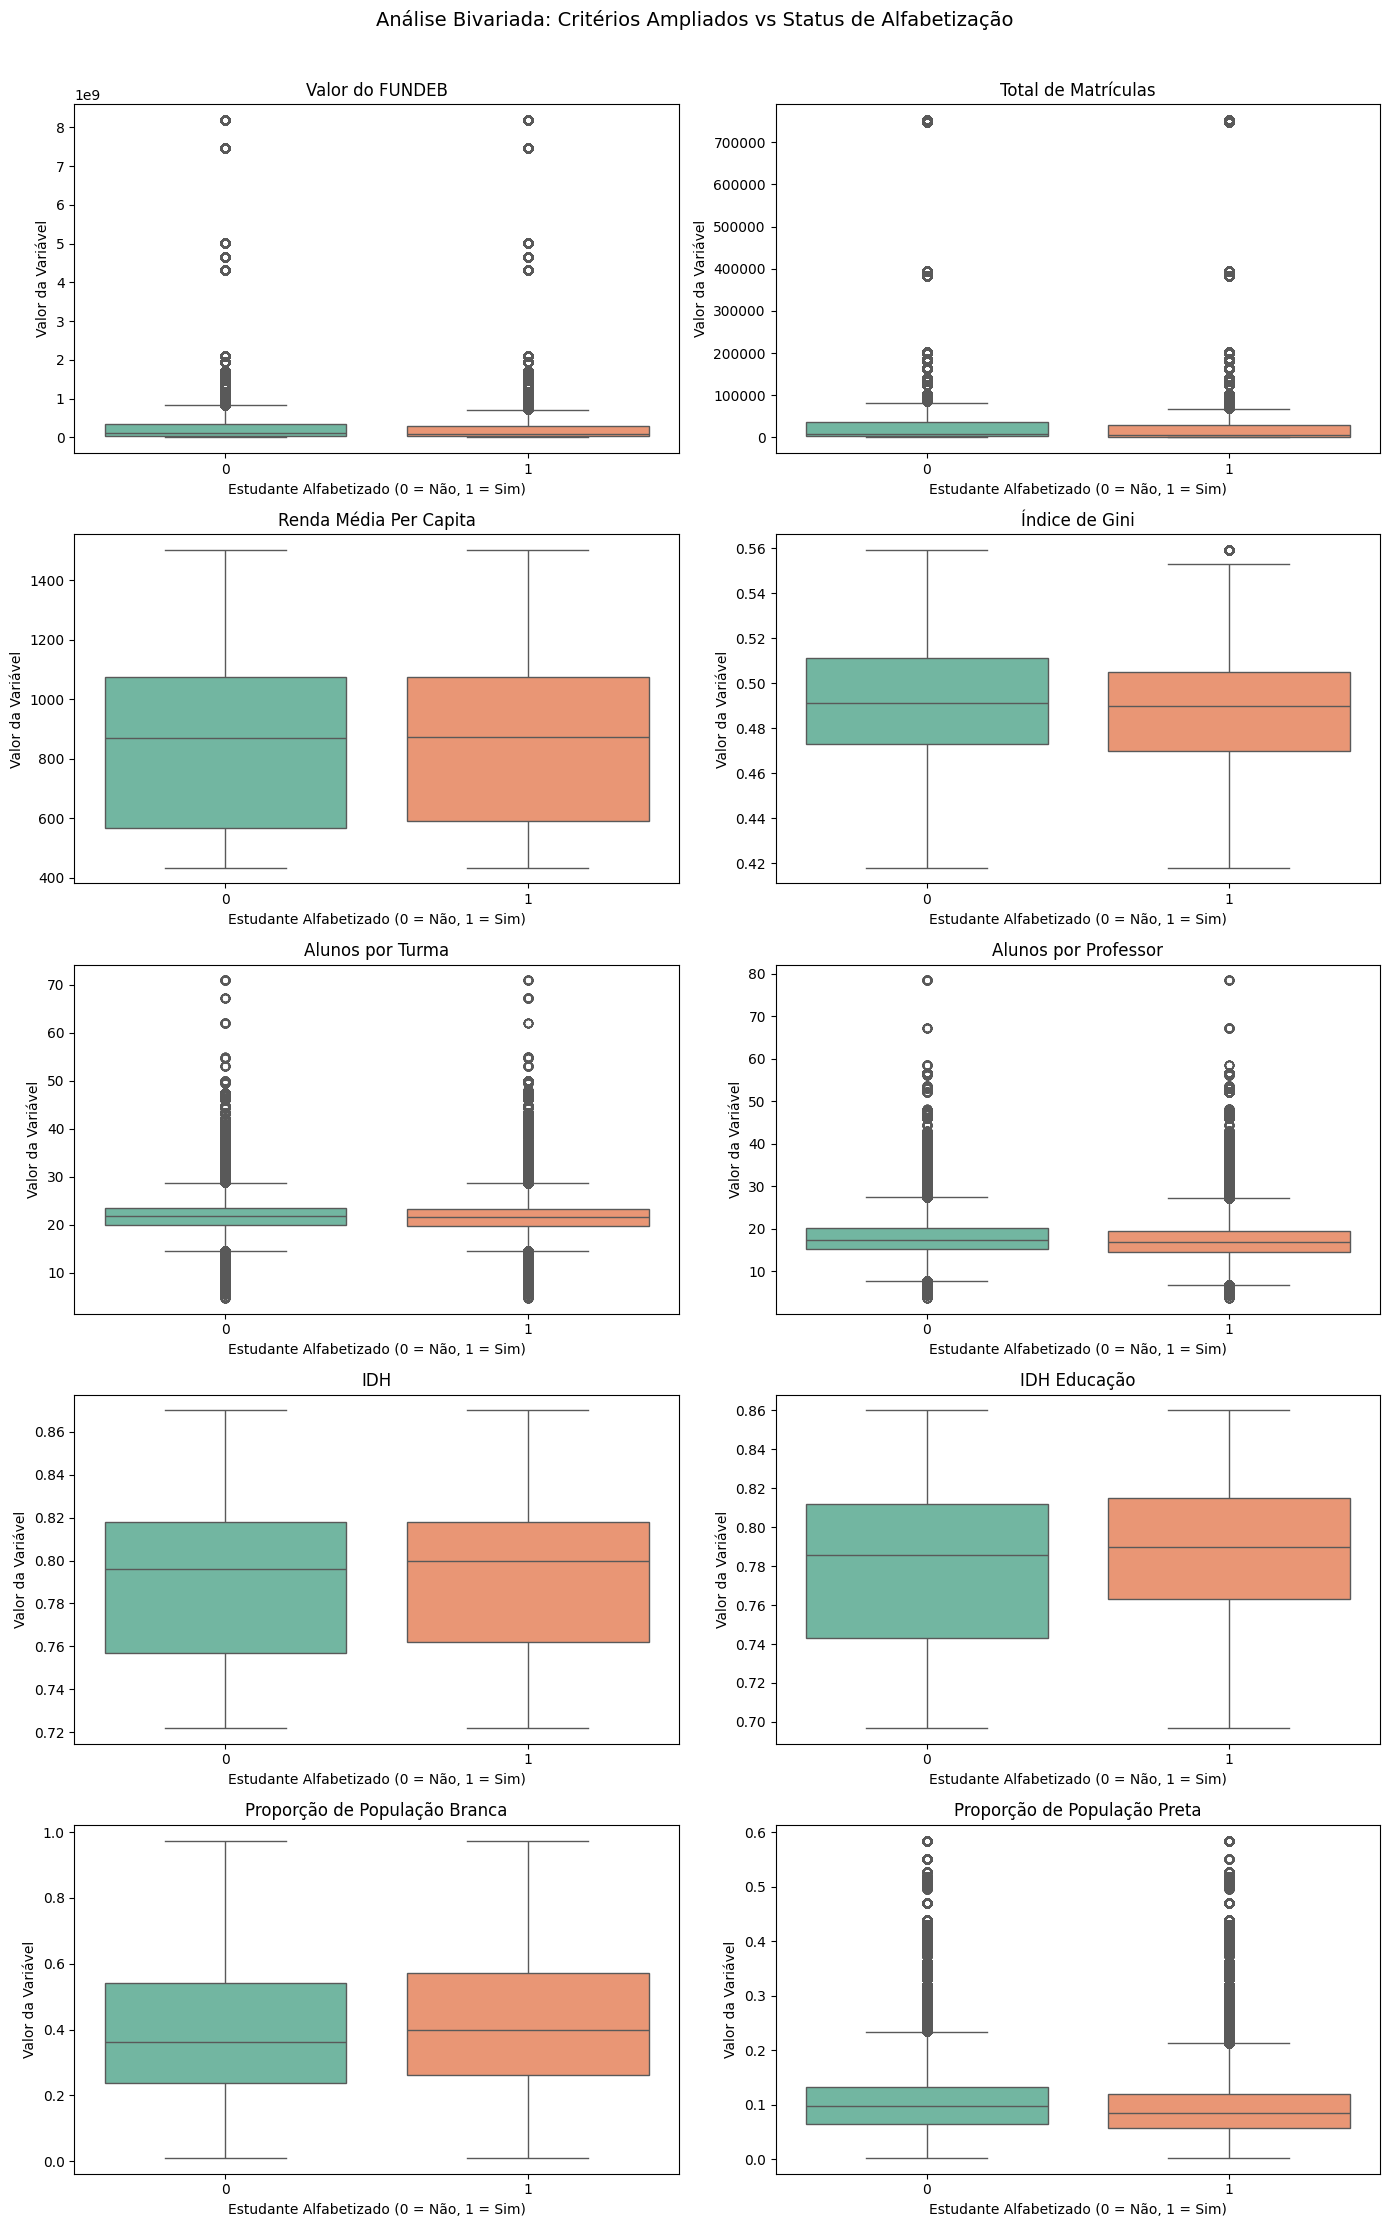

In [22]:
import seaborn as sns

vars_biv = [
    'fundeb_amount', 'total_enrollments',
    'income_per_capita_mean', 'gini_index',
    'students_per_class', 'students_per_teacher',
    'hdi', 'hdi_education',
    'pct_white', 'pct_black'
]

titulos_biv = [
    'Valor do FUNDEB', 'Total de Matrículas',
    'Renda Média Per Capita', 'Índice de Gini',
    'Alunos por Turma', 'Alunos por Professor',
    'IDH', 'IDH Educação',
    'Proporção de População Branca', 'Proporção de População Preta'
]

fig, axes = plt.subplots(5, 2, figsize=(14, 22))
axes = axes.flatten()

for i, col in enumerate(vars_biv):
    if col in df_EDA.columns and 'student_is_literate' in df_EDA.columns:
        sns.boxplot(
            x='student_is_literate', 
            y=col, 
            data=df_EDA, 
            ax=axes[i], 
            palette='Set2'
        )
        axes[i].set_title(titulos_biv[i])
        axes[i].set_xlabel('Estudante Alfabetizado (0 = Não, 1 = Sim)')
        axes[i].set_ylabel('Valor da Variável')

plt.suptitle('Análise Bivariada: Critérios Ampliados vs Status de Alfabetização', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

As distribuições do fundeb_amount e total_enrollments são altamente comprimidas próximo ao eixo inferior e apresentam grande similaridade entre os grupos de alunos alfabetizados e não alfabetizados, acompanhadas de outliers expressivos referentes a municípios com grandes redes e repasses massivos de recursos. Esse padrão foi discutido anteriormente. A renda média per capita e o índice de Gini demonstram comportamento quase idêntico em ambas as categorias, evidenciando que, de forma isolada, as métricas macroeconômicas municipais não criam uma linha de separação direta para o desfecho individual do aluno. No entanto, o índice de Gini possui um leve deslocamento de mediana para cima no caso dos alunos não alfabetizados. Embora, individualmente esse dado não seja tão evidente, é possível que tal padrão demonstre algum nível de impacto da desigualdade sobre a alfabetização. 

As medianas e a amplitude central da densidade de turmas e da carga docente permanecem estáveis e equiparadas nos dois grupos, refletindo um padrão estrutural de atendimento semelhante na rede. Nos dois casos há um deslocamento de outliers referentes à superlotação de turmas em alguns municípios. Sobre os box plot do hdi e hdi_education, identifica-se um sutil deslocamento positivo nas medianas e quartis para o grupo de estudantes alfabetizados (1), indicando que contextos estaduais com melhores indicadores de desenvolvimento humano e educacional tendem a concentrar margens ligeiramente mais favoráveis de alfabetização. 

As proporções demográficas municipais de população branca e preta apresentam leves variações nas distribuições entre os grupos, capturando gradientes socioespaciais e regionais reais do país que influenciam as disparidades estruturais de ensino. Pode-se observar que os alfabetizados possuem um leve deslocamento positivo para população branca mais elevada e um leve deslocamento para baixo em relação à população negra. Esses dados podem refletir condições estruturais de racismo e de recorte social, associado à população periférica e, por consequência, majoritariamente preta e parda.

A análise bivariada demonstra que os indicadores socioeconômicos, orçamentários, operacionais e raciais, quando analisados de forma isolada, possuem grande sobreposição entre os grupos de alunos alfabetizados e não alfabetizados. Embora sutis deslocamentos em variáveis como IDH e perfil demográfico revelem gradientes relevantes do ponto de vista descritivo, o baixo poder de separação univariada reforça que o sucesso na alfabetização infantil é um fenômeno complexo. Ele não depende de um único fator isolado, mas sim da interação multivariada, justificando o uso de modelos preditivos mais robustos.

### 2.2. Avaliação de Padrões Regionais e Risco Educacional

A ideia é agrupar e agregar os dados geograficamente, utilizando o recorte estadual (state_abbreviation) e municipal, para calcular a proporção média de alunos alfabetizados por região. O intuito é mapear as disparidades geográficas, visualizar macro-regiões que apresentam desempenhos educacionais semelhantes e municípios com baixa taxa de alfabetização. Seria impraticável realizar esse tipo de análise e apresentar os dados para cada município, individualmente. Por isso, optamos por ordenadar os municípios com menores taxas de alfabetização para entender onde estão localização e qual o perfil demográfico. Evitamos carregar os nomes dos das cidade e siglas dos Estados durante a busca das cidades com risco educacional, para evitar sobrecarga na memória RAM. Os dados serão acrescentados após a seleção dos municípios, via merge.

In [9]:
# Agrupamento de dados municipais
df_agrupado = df_EDA.groupby('city_code').agg(
    literacy_rate=('student_is_literate', 'mean'),
    total_students=('student_is_literate', 'count')
).reset_index()

# Filtro de amostra mínima (remover distorções de cidades com poucos registros)
df_risco_filtrado = df_agrupado[df_agrupado['total_students'] >= 50]

# Seleciona colunas adicionais para compor o perfil do município após a busca pelos municípios com risco
cols_desejadas = [
    'city_code', 'state_abbreviation', 'city_name',
    'pct_black', 'pct_brown', 'pct_indigenous',
    'income_per_capita_mean', 'hdi','gini_index'
]

# Garante que apenas as colunas que realmente existem no dataframe sejam utilizadas
cols_map = [col for col in cols_desejadas if col in df_EDA.columns]

# Extrai os valores únicos por município (operação extremamente leve para a RAM)
df_mapa = df_EDA[cols_map].drop_duplicates(subset=['city_code'])

# Mescla (Merge) as taxas calculadas com os dados socioeconômicos e demográficos
df_risco_final = df_risco_filtrado.merge(df_mapa, on='city_code', how='left')

# Ranqueamento - Ordena pelos menores índices de alfabetização
df_top_risco = df_risco_final.sort_values(by='literacy_rate', ascending=True).head(20)

print("--- TOP 20 MUNICÍPIOS DE MAIOR RISCO EDUCACIONAL (Com Perfil Socioeconômico) ---")
display(df_top_risco)

--- TOP 20 MUNICÍPIOS DE MAIOR RISCO EDUCACIONAL (Com Perfil Socioeconômico) ---


,city_code,literacy_rate,total_students,state_abbreviation,city_name,pct_black,pct_brown,pct_indigenous,income_per_capita_mean,hdi,gini_index
362,1707702,0.125561,223,TO,Filadélfia,0.129798,0.655213,0.001167,708.669983,0.777,0.497
1795,2805109,0.176190,210,SE,Pedrinhas,0.132234,0.673337,0.001487,575.070007,0.738,0.553
1910,2907202,0.192440,1746,BA,Casa Nova,0.120162,0.578684,0.003329,518.419983,0.734,0.511
1182,2410108,0.196000,250,RN,Poço Branco,0.108475,0.633979,0.000161,587.440002,0.744,0.530
2004,2915403,0.200913,219,BA,Itaju do Colônia,0.141295,0.526420,0.191486,518.419983,0.734,0.511
330,1703008,0.210084,238,TO,Babaçulândia,0.124492,0.672208,0.001650,708.669983,0.777,0.497
1167,2408706,0.210526,57,RN,Paraú,0.070411,0.612462,0.000000,587.440002,0.744,0.530
1848,2902252,0.212560,207,BA,Arataca,0.228633,0.628201,0.006182,518.419983,0.734,0.511
1427,2514651,0.218750,64,PB,São José do Brejo do Cruz,0.114185,0.563273,0.000000,544.919983,0.737,0.535
1798,2805406,0.231628,1075,SE,Poço Redondo,0.074913,0.685965,0.000359,575.070007,0.738,0.553


Os dados revelam que o maior déficit de alfabetização não ocorre de forma aleatória, mas agrupa-se em cidades de pequeno porte populacional, localizadas predominantemente em zonas rurais e áreas de interior. também é relevante notar que a porcentagem de pessoas negras (pretos+pardos) nesses municípios, em sua maioria, fica próximo ou ultrapassa os 70%. Outro dado relevante é que em todas as cidades ranqueadas, a renda media per capita, obtida pelo dataset de idhm a nível estadual, é inferior ao dado de renda média total, encontrado na etapa de estaística descritiva. Ou seja, são todas regiões pobres. 

O mapeamento destaca que os municípios mais críticos estão concentrados majoritariamente nos estados da Bahia (BA), Tocantins (TO) e Rio Grande do Norte (RN). Esse padrão regional reforça que o isolamento geográfico e as limitações de infraestrutura inerentes a pequenos municípios interioranos são fortes agravantes para o atraso educacional. O risco educacional é sistêmico em pequenas cidades do interior de estados específicos, indicando que a localização e a escala populacional (volume de alunos) são variáveis fundamentais.

C:\Users\andre\AppData\Local\Temp\ipykernel_15920\1289846015.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_uf_literacy = df_EDA.groupby('state_abbreviation')['student_is_literate'].mean().reset_index()
C:\Users\andre\AppData\Local\Temp\ipykernel_15920\1289846015.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


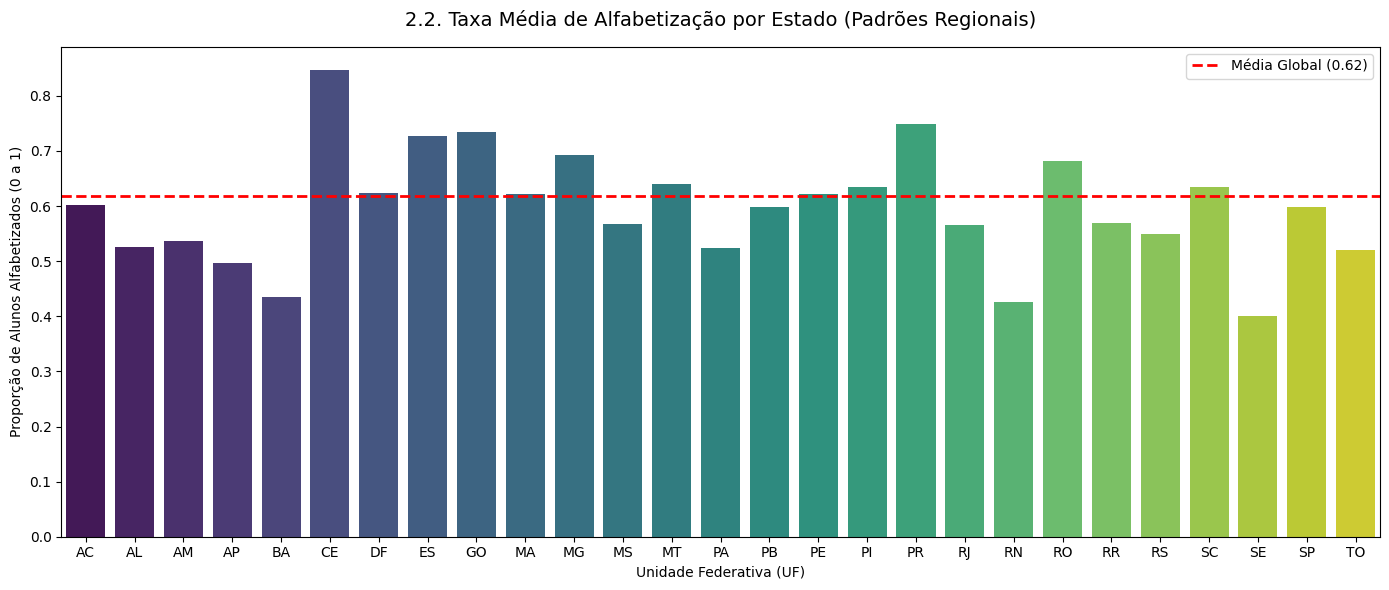

In [11]:
# Calcular a taxa média de alfabetização por Estado (UF)
# Como a variável alvo (student_is_literate) é binária (0 ou 1), a média representa a taxa de alfabetização
df_uf_literacy = df_EDA.groupby('state_abbreviation')['student_is_literate'].mean().reset_index()

# Ordenar do maior para o menor desempenho para facilitar a identificação de padrões
df_uf_literacy = df_uf_literacy.sort_values(by='student_is_literate', ascending=False)

# Criar a visualização
plt.figure(figsize=(14, 6))
sns.barplot(
    data=df_uf_literacy, 
    x='state_abbreviation', 
    y='student_is_literate', 
    palette='viridis'
)

# Adicionar linha de referência com a média global do dataset
media_nacional = df_EDA['student_is_literate'].mean()
plt.axhline(media_nacional, color='red', linestyle='--', linewidth=2, label=f'Média Global ({media_nacional:.2f})')

plt.title('2.2. Taxa Média de Alfabetização por Estado (Padrões Regionais)', fontsize=14, pad=15)
plt.xlabel('Unidade Federativa (UF)')
plt.ylabel('Proporção de Alunos Alfabetizados (0 a 1)')
plt.legend()
plt.tight_layout()
plt.show()

Os padrões encontrados mostram que os três Estados (BA, RN e TO) que aparecem na análise anterior dos municípios de risco estão bastante abaixo da média de proporção de alunos alfabetizados. SE, que também apresenta municípios de risco, é o Estado com menor proporção de alunos alfabetizados do Brasil. Vemos também o destaque positivos os Estados do PR, RO, ES, GO e MG que se destacaram bem acima da média. Em especial, verificamos que o CE ficou em primeiro lugar entre os Estados com maior proporção de alunos alfabetizados. O Ceará é um Estado conhecido pela revolução educacional que desenvolveu nas últimas duas décadas. Repetidamente é o Estado que mais aprova para o ENEM, carreiras militares e sempre obtém excelente desempenho em Olimpíadas estudantis, como a Olimpíada de matemática. Esse dado reforça um insight muito importante para a educação brasileira. A educação de base tem um efeito transformador, que impacta toda a cadeia de conhecimento do país.

### 3.1. Matriz de Correlação

O objetivo desse tópico é calcular a matriz de correlação para todas as variáveis contínuas, excluindo identificadores e códigos geográficos (city_code, state_abbreviation, IDs, etc.). O objetivo é identificar quais pares de variáveis apresentam alta colinearidade (redundância) e como elas se correlacionam com a taxa de alfabetização.

In [13]:
# Seleciona exclusivamente variáveis numéricas
df_numerico = df_EDA.select_dtypes(include=[np.number])

# Define e remove colunas de identificação e códigos geográficos
# Adicionei possíveis IDs comuns de tabelas educacionais para garantir a limpeza
colunas_remover = ['year', 'state_code', 'city_code', 'school_id']

# Filtro para tentar remover apenas as colunas que realmente existirem no dataframe
colunas_remover = [col for col in colunas_remover if col in df_numerico.columns]
df_correlacao = df_numerico.drop(columns=colunas_remover)

# 3. Calcular a matriz de correlação de Pearson
matriz_corr = df_correlacao.corr(method='pearson')

# 4. Exibir a matriz completa
print("--- Matriz de Correlação Numérica (Pearson) ---")
display(matriz_corr)

# 5. Otimização para leitura: Extrair e listar apenas os pares com alta multicolinearidade
# Transforma a matriz numa lista de pares para facilitar a inspeção no console
pares_corr = matriz_corr.unstack().reset_index()
pares_corr.columns = ['Variavel_1', 'Variavel_2', 'Correlacao']

# Filtra valores absolutos acima de 0.75 (ou -0.75), ignorando a correlação de 1.0 da variável com ela mesma
pares_alta_corr = pares_corr[
    (pares_corr['Variavel_1'] != pares_corr['Variavel_2']) & 
    (pares_corr['Correlacao'].abs() > 0.75)
]

# Remove pares duplicados (ex: A-B e B-A) e ordena do maior para o menor
pares_alta_corr = pares_alta_corr.drop_duplicates(subset=['Correlacao']).sort_values(by='Correlacao', ascending=False)

print("\n--- Alerta de Multicolinearidade: Pares Altamente Correlacionados (|r| > 0.75) ---")
display(pares_alta_corr)

--- Matriz de Correlação Numérica (Pearson) ---


,education_network_type,student_exam_weight,student_exam_score,student_is_literate,city_percentage_literate_students,city_average_exam_score,state_percentage_literate_students,state_average_exam_score,households,area,...,students_per_teacher,students_per_class,pct_enrollments_zero_class_schools,hdi,hdi_life_expectancy,hdi_education,hdi_income,gini_index,income_per_capita_mean,age_lag_2y_basic_rate
education_network_type,1.000000,-0.017161,-0.000724,-0.009990,-0.027655,0.000921,-0.036807,-0.002245,-0.245267,-0.016051,...,0.063091,-0.036714,0.041947,-0.218333,-0.241500,-0.171434,-0.204758,0.060955,-0.223421,0.155438
student_exam_weight,-0.017161,1.000000,-0.076126,-0.056908,-0.105347,-0.121620,-0.065127,-0.092322,0.026680,0.028828,...,0.032823,0.034287,-0.023175,0.044264,0.012035,0.019271,0.065014,-0.029117,0.064295,0.040901
student_exam_score,-0.000724,-0.076126,1.000000,0.795723,0.391617,0.419796,0.294840,0.317125,-0.033292,-0.040559,...,-0.068586,-0.032119,-0.014558,0.047740,0.107129,0.080479,-0.005553,-0.063667,-0.010121,-0.176714
student_is_literate,-0.009990,-0.056908,0.795723,1.000000,0.322684,0.301036,0.237358,0.220067,-0.021233,-0.030259,...,-0.065522,-0.028744,-0.020262,0.072475,0.093685,0.088254,0.038779,-0.079379,0.033255,-0.147164
city_percentage_literate_students,-0.027655,-0.105347,0.391617,0.322684,1.000000,0.933171,0.734606,0.681942,-0.067983,-0.094905,...,-0.202187,-0.090168,-0.061872,0.222091,0.290566,0.271559,0.116910,-0.243460,0.100240,-0.455091
city_average_exam_score,0.000921,-0.121620,0.419796,0.301036,0.933171,1.000000,0.701850,0.754770,-0.080765,-0.097517,...,-0.162612,-0.077609,-0.034217,0.112322,0.255340,0.190767,-0.015152,-0.149893,-0.025662,-0.419901
state_percentage_literate_students,-0.036807,-0.065127,0.294840,0.237358,0.734606,0.701850,1.000000,0.929526,-0.015797,-0.097092,...,-0.170431,-0.030443,-0.114379,0.299050,0.391283,0.369613,0.154243,-0.325473,0.131600,-0.617242
state_average_exam_score,-0.002245,-0.092322,0.317125,0.220067,0.681942,0.754770,0.929526,1.000000,-0.029084,-0.104456,...,-0.127039,-0.027558,-0.088128,0.150745,0.339840,0.256117,-0.019596,-0.192285,-0.032554,-0.554982
households,-0.245267,0.026680,-0.033292,-0.021233,-0.067983,-0.080765,-0.015797,-0.029084,1.000000,-0.036023,...,-0.006504,0.193729,-0.144518,0.287805,0.081837,0.330581,0.259314,0.170557,0.281580,-0.144691
area,-0.016051,0.028828,-0.040559,-0.030259,-0.094905,-0.097517,-0.097092,-0.104456,-0.036023,1.000000,...,0.226143,0.137607,0.211413,-0.154843,-0.139096,-0.126767,-0.151116,-0.001139,-0.152757,0.202914



--- Alerta de Multicolinearidade: Pares Altamente Correlacionados (|r| > 0.75) ---


,Variavel_1,Variavel_2,Correlacao
342,households,population_total,0.999540
597,population_total,total_teachers,0.999411
351,households,total_teachers,0.998761
596,population_total,total_enrollments,0.998732
925,total_enrollments,total_teachers,0.998438
926,total_enrollments,total_classes,0.998316
598,population_total,total_classes,0.997788
967,total_teachers,total_classes,0.997076
350,households,total_enrollments,0.996964
352,households,total_classes,0.996367


# Correlação

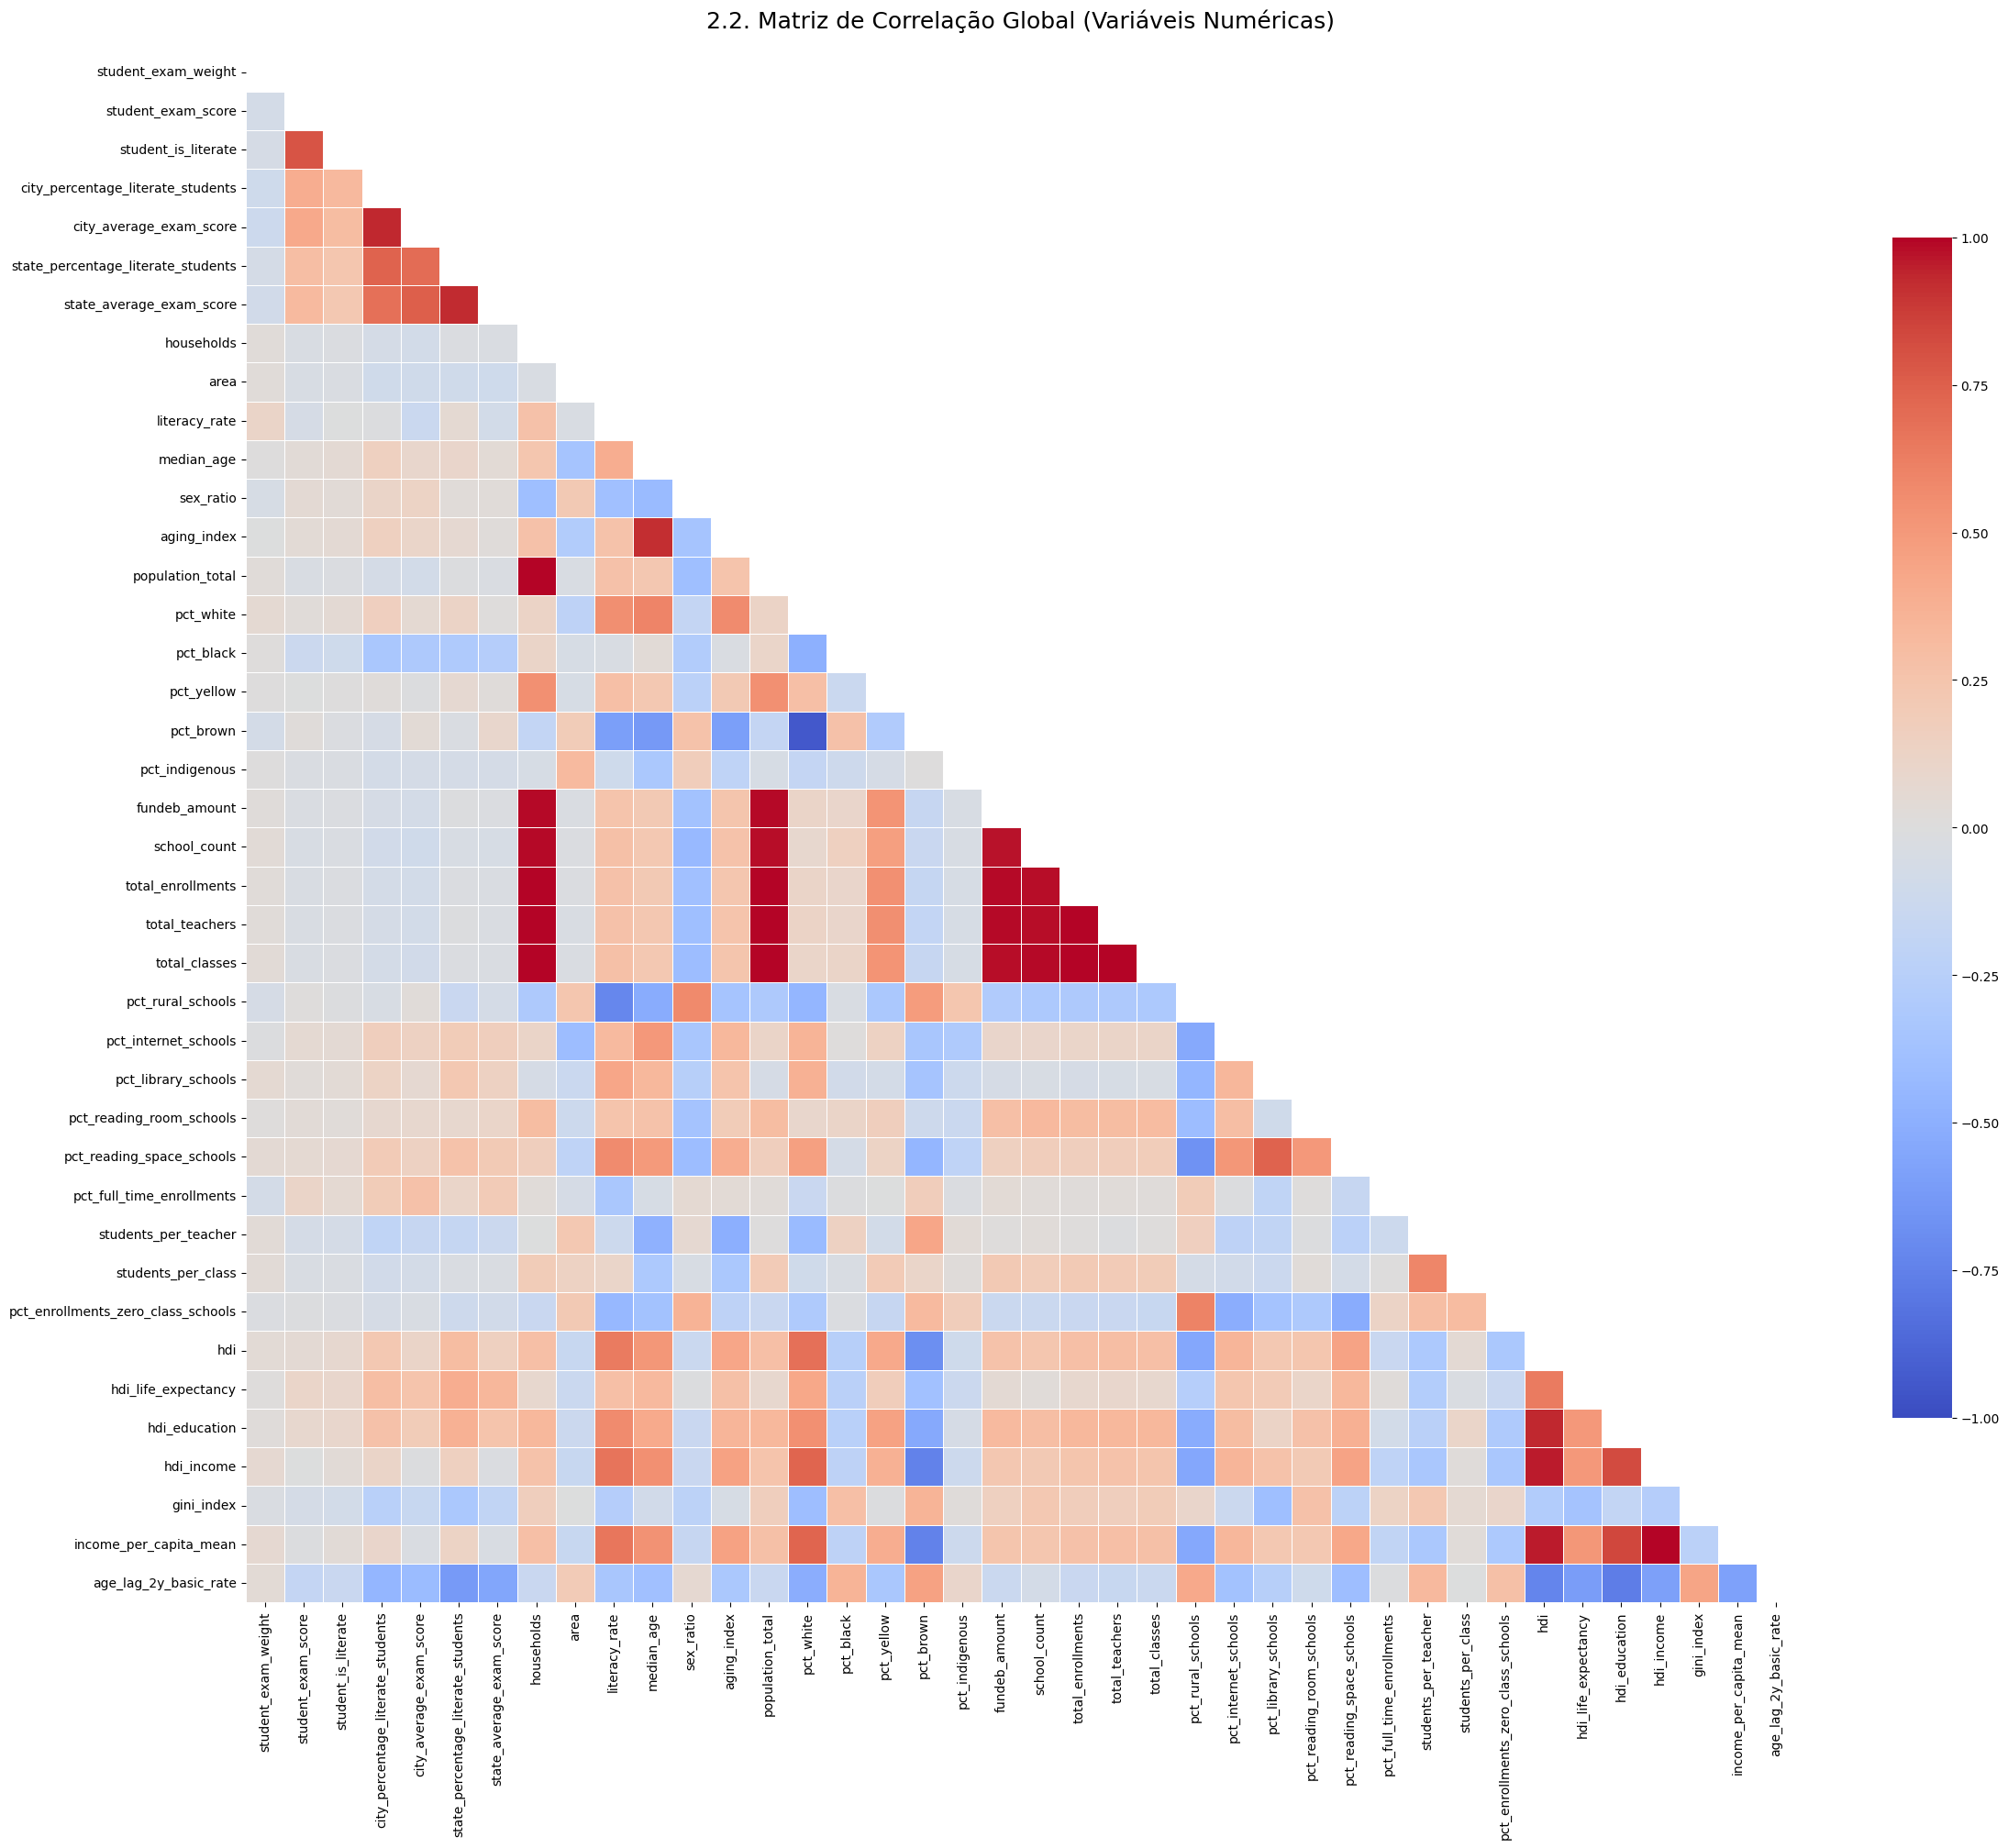

In [15]:
import numpy as np

# 1. Selecionar estritamente variáveis numéricas
df_numerico = df_EDA.select_dtypes(include=[np.number])

# 2. Definir IDs e códigos estruturais a serem removidos
colunas_remover = ['year', 'state_code', 'city_code', 'education_network_type']

# Filtro de segurança: manter na lista de exclusão apenas o que existir no df_numerico
colunas_remover = [col for col in colunas_remover if col in df_numerico.columns]

# Criar DataFrame exclusivo para a correlação
df_correlacao = df_numerico.drop(columns=colunas_remover)

# 3. Calcular a Matriz de Correlação de Pearson
matriz_corr = df_correlacao.corr()

# 4. Plotagem do Heatmap
# Máscara para esconder o triângulo superior (espelhado) e focar nos dados úteis
mask = np.triu(np.ones_like(matriz_corr, dtype=bool))

plt.figure(figsize=(24, 20)) # Tamanho expandido devido ao alto número de features
sns.heatmap(
    matriz_corr, 
    mask=mask, 
    cmap='coolwarm', 
    vmax=1.0, vmin=-1.0, 
    center=0, 
    square=True, 
    linewidths=.5, 
    cbar_kws={"shrink": .75}
    # annot=True foi omitido intencionalmente: com ~40 variáveis, os números ficariam ilegíveis
)

plt.title('2.2. Matriz de Correlação Global (Variáveis Numéricas)', fontsize=18, pad=20)
plt.tight_layout()
plt.show()